## importing the necessary libraries

In [18]:
import tensorflow as tf 
from tensorflow import keras

## load the MNIST dataset, which consists of 60,000 training images and 10,000 test images of handwritten digits

In [19]:
# Load the MNIST dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

## Preprocess the data

In [20]:
# Preprocess the data
x_train = x_train.reshape((60000, 28, 28, 1)) / 255.0  # Reshape and normalize training images
x_test = x_test.reshape((10000, 28, 28, 1)) / 255.0    # Reshape and normalize test images
y_train = keras.utils.to_categorical(y_train)         # Convert training labels to categorical format
y_test = keras.utils.to_categorical(y_test)           # Convert test labels to categorical format

To preprocess the data, we take the following steps:

We reshape the training and test images to have a shape of (num_samples, 28, 28, 1), where num_samples is the number of images, and each image is a 28x28 grayscale image with a single channel.
We normalize the pixel values of the images by dividing them by 255.0 to scale them between 0 and 1.
We convert the training and test labels to a categorical format using keras.utils.to_categorical(), which converts the integer labels to one-hot encoded vectors.

## Defining the model architecture with batch normalization

In [21]:
# Define the model architecture
model = keras.Sequential([
    keras.layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    keras.layers.BatchNormalization(),
    keras.layers.Conv2D(64, (3, 3), activation='relu'),
    keras.layers.BatchNormalization(),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.BatchNormalization(),
    keras.layers.Dense(10, activation='softmax')
])

To do that, we take the following steps:

1. We define the model architecture using the keras.Sequential API, which allows stacking layers sequentially.
2. The model consists of convolutional layers (Conv2D) for feature extraction, followed by batch normalization layers (BatchNormalization) to normalize the activations.
3. We use max pooling (MaxPooling2D) for downsampling the feature maps.
4. We flatten the feature maps (Flatten) before passing them to the dense layers.
5. The final dense layer has 10 units with softmax activation, corresponding to the 10 classes of digits.

## Compile the model

In [22]:
# Compile the model
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

## Train the model

In [23]:
# Train the model
history=model.fit(x_train, y_train, batch_size=128, epochs=5, validation_data=(x_test, y_test))

Epoch 1/5
469/469 [==============================] - 82s 171ms/step - loss: 0.1011 - accuracy: 0.9701 - val_loss: 0.6648 - val_accuracy: 0.7812
Epoch 2/5
469/469 [==============================] - 79s 169ms/step - loss: 0.0312 - accuracy: 0.9909 - val_loss: 0.0481 - val_accuracy: 0.9848
Epoch 3/5
469/469 [==============================] - 81s 172ms/step - loss: 0.0158 - accuracy: 0.9956 - val_loss: 0.0393 - val_accuracy: 0.9887
Epoch 4/5
469/469 [==============================] - 82s 175ms/step - loss: 0.0105 - accuracy: 0.9969 - val_loss: 0.0377 - val_accuracy: 0.9877
Epoch 5/5
469/469 [==============================] - 79s 168ms/step - loss: 0.0079 - accuracy: 0.9978 - val_loss: 0.0427 - val_accuracy: 0.9863


In [24]:
from matplotlib import pyplot

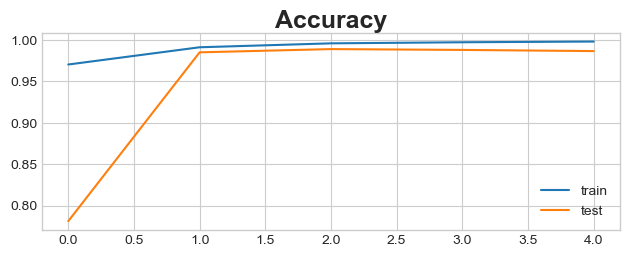

In [30]:
# plot accuracy learning curves
pyplot.subplot(212)
pyplot.title('Accuracy', pad=-40)
pyplot.plot(history.history['accuracy'], label='train')
pyplot.plot(history.history['val_accuracy'], label='test')
pyplot.legend()
pyplot.show()

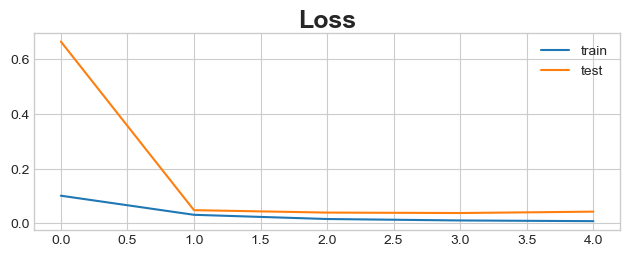

In [31]:
# plot loss learning curves
pyplot.subplot(212)
pyplot.title('Loss', pad=-40)
pyplot.plot(history.history['loss'], label='train')
pyplot.plot(history.history['val_loss'], label='test')
pyplot.legend()
pyplot.show()